Enter your IBM Quantum API key:  ········
Enter your IBM Quantum instance / CRN:  crn:v1:bluemix:public:quantum-computing:us-east:a/00b3915f8e7243f7a01812846e4b3fa3:c5c6654f-1782-4b1a-9ec3-6b7cea9475b3::


qiskit_runtime_service._discover_account:WARNING:2026-10-12 16:03:40,233: Loading account with the given token. A saved account will not be used.


Connected to IBM Quantum!
Backend: ibm_kingston

Circuit A: Bias toward 0


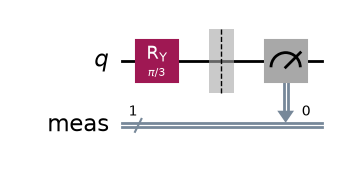


Circuit B: Bias toward 1


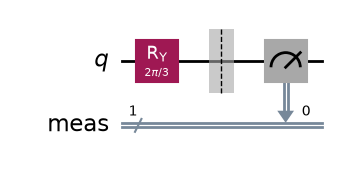


PREDICTED PROBABILITIES
Circuit A: P(0) = 75%, P(1) = 25%
Circuit B: P(0) = 25%, P(1) = 75%


C:\Users\pravallika malluri\AppData\Local\Temp\ipykernel_9564\3144961542.py:62: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)



Job ID: db6bf72mb58s738bhs20

ACTUAL RESULTS (100 shots each)
Circuit A: {'1': 55, '0': 45}
Circuit B: {'0': 20, '1': 80}

Circuit A
0: 45/ 100 = 45.0%
1: 55/ 100 = 55.0%

Circuit B
0: 20/ 100 = 20.0%
1: 80/ 100 = 80.0%


In [1]:

from getpass import getpass
import math
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.visualization import plot_histogram

# 1. Connect to IBM Quantum
api_key = getpass("Enter your IBM Quantum API key: ")
instance = input("Enter your IBM Quantum instance / CRN: ").strip()

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=api_key,
    instance=instance
)

print("Connected to IBM Quantum!")

# 2. Select an available real quantum backend
backend = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=1
)
print("Backend:", backend.name)

# 3. Circuit A: Bias toward 0
# RY(pi/3) gives ideal P(0) = 75%, P(1) = 25%
qc_a = QuantumCircuit(1)
qc_a.ry(math.pi / 3, 0)
qc_a.measure_all()

# 4. Circuit B: Bias toward 1
# RY(2*pi/3) gives ideal P(0) = 25%, P(1) = 75%
qc_b = QuantumCircuit(1)
qc_b.ry(2 * math.pi / 3, 0)
qc_b.measure_all()

# 5. Display the circuits
print("\nCircuit A: Bias toward 0")
display(qc_a.draw("mpl"))

print("\nCircuit B: Bias toward 1")
display(qc_b.draw("mpl"))

# 6. Predictions
print("\nPREDICTED PROBABILITIES")
print("Circuit A: P(0) = 75%, P(1) = 25%")
print("Circuit B: P(0) = 25%, P(1) = 75%")

# 7. Transpile for the selected backend
pm = generate_preset_pass_manager(
    backend=backend,
    optimization_level=1
)
isa_circuits = pm.run([qc_a, qc_b])

# 8. Execute each circuit for 100 shots
sampler = Sampler(mode=backend)
job = sampler.run(isa_circuits, shots=100)

print("\nJob ID:", job.job_id())
result = job.result()

# 9. Get measurement counts
counts_a = result[0].data.meas.get_counts()
counts_b = result[1].data.meas.get_counts()

print("\nACTUAL RESULTS (100 shots each)")
print("Circuit A:", counts_a)
print("Circuit B:", counts_b)

# 10. Plot histograms
plot_histogram(
    [counts_a, counts_b],
    legend=["Circuit A: Bias toward 0",
            "Circuit B: Bias toward 1"],
    title="Challenge 2: Make the Quantum Coin Biased"
)
plt.show()

# 11. Compare actual probabilities
def show_percentages(name, counts):
    total = sum(counts.values())
    zeros = counts.get("0", 0)
    ones = counts.get("1", 0)

    print(f"\n{name}")
    print(f"0: {zeros}/ {total} = {zeros / total * 100:.1f}%")
    print(f"1: {ones}/ {total} = {ones / total * 100:.1f}%")

show_percentages("Circuit A", counts_a)
show_percentages("Circuit B", counts_b)
